# Urban Bike-Sharing Demand Prediction
## Feature Engineering Pipeline

### Methodology & Target Leakage Prevention
Historical lag and rolling-window features are generated from preceding station-level demand observations. The features use past demand values rather than current or future demand. The final feature audit verifies that no current/future target leakage is present and that lag alignment is correct.

Feature engineering is strictly causal: all rolling and lag features are calculated from historical observations prior to timestamp $t$ using station-wise shifting (`shift(1)`).

### Feature Categories Included
The engineered features encompass:
- **Temporal Calendar Features**: discrete calendar coordinates (`hour`, `day`, `weekday`, `month`, `year`, `is_weekend`, `is_weekday`, etc.)
- **Cyclic Time Features**: continuous trigonometric encodings ($\sin$ and $\cos$ transformations for hour, weekday, and month)
- **Peak-Hour Features**: domain commute indicators (`morning_peak`, `evening_peak`, `peak_hour`)
- **Interaction Features**: cross-terms capturing joint temporal dynamics (`hour_weekday`, `weekend_hour`, `weekday_hour`, `month_hour`)
- **Lag Features**: short-term and diurnal/weekly memory lags (`lag_1h` to `lag_12h`, `lag_24h`, `lag_48h`, `lag_72h`, `lag_168h`)
- **Same-Hour Historical Features**: historical day-lag alignments
- **Rolling Statistical Features**: multi-scale moving statistics (`rolling_mean`, `rolling_std`, `rolling_min`, `rolling_max`, `rolling_median`) computed over past windows
- **Ratio / History-Based Features**: normalized momentum indicators (`lag_1h_ratio_24h`, `lag_24h_ratio_week`, `rolling_ratio_24h_168h`)

No weather features, station capacity features, or live dock/bike availability features are included.

### Feature Audit & Final Feature Count
A total of 62 candidate model features are engineered in this pipeline. The subsequent feature audit (`final_feature_audit.ipynb`) rigorously removes 8 risky features (5 non-causal global aggregates and 3 target-dependent demand-change features), yielding exactly **54 certified, production-safe features**.

### Chronological Train / Validation / Test Partitioning
The dataset is split strictly chronologically (approximately 70% / 15% / 15%) without random shuffling:
- **TRAIN Set**: 861,560 rows (2013-08-29 09:00 -> 2015-01-24 04:00) - ~70%
- **VALIDATION Set**: 184,590 rows (2015-01-24 05:00 -> 2015-05-14 01:00) - ~15%
- **TEST Set**: 184,660 rows (2015-05-14 02:00 -> 2015-08-31 23:00) - ~15%
- **Total**: 1,230,810 station-hour records.


In [1]:
# ================================================================
# URBAN BIKE-SHARING DEMAND PREDICTION
# FEATURE ENGINEERING
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


In [2]:
# ================================================================
# CONFIGURATION
# ================================================================

def find_file(filename, search_subpaths=None):
    candidates = [
        filename,
        os.path.join(os.getcwd(), filename),
        os.path.join('/content', filename),
        os.path.join(os.path.dirname(os.getcwd()), filename)
    ]
    if search_subpaths:
        for sp in search_subpaths:
            candidates.extend([
                sp,
                os.path.join(os.getcwd(), sp),
                os.path.join('/content', sp),
                os.path.join('..', sp),
                os.path.join(os.path.dirname(os.getcwd()), sp),
                os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), sp)
            ])
    for c in candidates:
        if os.path.exists(c):
            return os.path.abspath(c)
    return filename


INPUT_PATH = find_file("station_hourly_demand.csv", [
    "data/preprocessed/station_hourly_demand.csv",
    "preprocessed/station_hourly_demand.csv"
])

OUTPUT_DIR = "data/features"
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUT_PATH = os.path.join(OUTPUT_DIR, "station_hourly_demand_features.csv")


In [3]:
# ================================================================
# HEADER
# ================================================================

print("=" * 70)
print("URBAN BIKE-SHARING DEMAND PREDICTION")
print("FEATURE ENGINEERING")
print("=" * 70)


URBAN BIKE-SHARING DEMAND PREDICTION
FEATURE ENGINEERING


In [4]:
# ================================================================
# 1. LOAD PREPROCESSED DATA
# ================================================================

print("\n1. LOADING PREPROCESSED DATA")
print("-" * 70)

# Check if preprocessed dataset exists
if not os.path.exists(INPUT_PATH):
    # Check if trip.csv is available to auto-generate station_hourly_demand.csv
    trip_file = find_file("trip.csv", ["data/raw/trip.csv", "raw/trip.csv"])
    if os.path.exists(trip_file):
        print(f"station_hourly_demand.csv not found directly, but found: {trip_file}")
        print("Auto-generating station_hourly_demand.csv on the fly from trip.csv...")
        raw_df = pd.read_csv(trip_file)
        raw_df["start_date_parsed"] = pd.to_datetime(raw_df["start_date"], errors="coerce", format="mixed")
        raw_df = raw_df.dropna(subset=["start_date_parsed", "start_station_id", "start_station_name"]).copy()
        raw_df["start_station_id"] = pd.to_numeric(raw_df["start_station_id"], errors="coerce").astype(int)
        raw_df["hour_timestamp"] = raw_df["start_date_parsed"].dt.floor("h")
        st_map = raw_df[["start_station_id", "start_station_name"]].drop_duplicates().sort_values("start_station_id")
        h_demand = raw_df.groupby(["start_station_id", "hour_timestamp"]).size().reset_index(name="demand")
        st_arr = raw_df["start_station_id"].drop_duplicates().sort_values().to_numpy()
        h_range = pd.date_range(start=raw_df["hour_timestamp"].min(), end=raw_df["hour_timestamp"].max(), freq="h")
        grid_df = pd.MultiIndex.from_product([st_arr, h_range], names=["start_station_id", "hour_timestamp"]).to_frame(index=False)
        df = grid_df.merge(h_demand, on=["start_station_id", "hour_timestamp"], how="left")
        df["demand"] = df["demand"].fillna(0).astype(int)
        df = df.merge(st_map, on="start_station_id", how="left")
        if "special_event" in raw_df.columns:
            raw_df["date_key"] = raw_df["start_date_parsed"].dt.date
            ev_map = raw_df.groupby("date_key")["special_event"].first().to_dict()
            d_series = pd.to_datetime(df["hour_timestamp"]).dt.date
            df["special_event"] = d_series.map(ev_map).fillna("No Event")
            df = df[["start_station_id", "start_station_name", "hour_timestamp", "special_event", "demand"]]
        else:
            df = df[["start_station_id", "start_station_name", "hour_timestamp", "demand"]]
        
        # Save so subsequent cells find it
        os.makedirs(os.path.dirname(INPUT_PATH) if os.path.dirname(INPUT_PATH) else ".", exist_ok=True)
        df.to_csv(INPUT_PATH, index=False)
        for extra in ["station_hourly_demand.csv", "../data/preprocessed/station_hourly_demand.csv"]:
            try:
                os.makedirs(os.path.dirname(extra) if os.path.dirname(extra) else ".", exist_ok=True)
                df.to_csv(extra, index=False)
            except Exception:
                pass
        print("Auto-preprocessing completed successfully!")
    else:
        raise FileNotFoundError(
            f"Neither station_hourly_demand.csv nor trip.csv was found at: {INPUT_PATH}.\n"
            "Please upload trip.csv or station_hourly_demand.csv to Google Colab."
        )
else:
    df = pd.read_csv(INPUT_PATH)

print("Dataset loaded successfully.")
print(f"Rows    : {len(df):,}")
print(f"Columns : {len(df.columns)}")

required_columns = [
    "start_station_id",
    "start_station_name",
    "hour_timestamp",
    "demand"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("All required columns are available.")



1. LOADING PREPROCESSED DATA
----------------------------------------------------------------------
Dataset loaded successfully.
Rows    : 1,230,810
Columns : 5
All required columns are available.


### 📌 Findings & Interpretation: Data Loading
* **Input Volume**: Loaded 1,230,810 continuous station-hour records with confirmed schema integrity.


In [5]:
# ================================================================
# 2. CONVERT TIMESTAMP
# ================================================================

print("\n2. CONVERTING TIMESTAMP")
print("-" * 70)

df["hour_timestamp"] = pd.to_datetime(
    df["hour_timestamp"],
    errors="coerce"
)

invalid_timestamps = df["hour_timestamp"].isna().sum()

print(f"Invalid timestamps: {invalid_timestamps}")

if invalid_timestamps > 0:
    raise ValueError(
        "Invalid timestamps found."
    )

print(
    f"Start: {df['hour_timestamp'].min()}"
)
print(
    f"End  : {df['hour_timestamp'].max()}"
)



2. CONVERTING TIMESTAMP
----------------------------------------------------------------------
Invalid timestamps: 0
Start: 2013-08-29 09:00:00
End  : 2015-08-31 23:00:00


In [6]:
# ================================================================
# 3. SORT DATA CHRONOLOGICALLY
# ================================================================

print("\n3. SORTING DATA")
print("-" * 70)

df = df.sort_values(
    ["start_station_id", "hour_timestamp"]
).reset_index(drop=True)

print("Data sorted by station and timestamp.")



3. SORTING DATA
----------------------------------------------------------------------
Data sorted by station and timestamp.


### 📌 Findings & Interpretation: Temporal Alignment
* **Sorting**: Sorted by station and timestamp to ensure forward shifts strictly access historical observations.


In [7]:
# ================================================================
# 4. CHECK STATION-HOUR DUPLICATES
# ================================================================

print("\n4. CHECKING DUPLICATES")
print("-" * 70)

duplicates = df.duplicated(
    subset=[
        "start_station_id",
        "hour_timestamp"
    ]
).sum()

print(
    f"Duplicate station-hour records: {duplicates}"
)

if duplicates > 0:
    raise ValueError(
        "Duplicate station-hour records detected."
    )



4. CHECKING DUPLICATES
----------------------------------------------------------------------


Duplicate station-hour records: 0


### 📌 Findings & Interpretation: Key Uniqueness
* **Audit**: Exactly 0 duplicate station-hour records found before computing lags.


In [8]:
# ================================================================
# 5. CALENDAR FEATURES
# ================================================================

print("\n5. CREATING CALENDAR FEATURES")
print("-" * 70)

df["hour"] = df["hour_timestamp"].dt.hour
df["day"] = df["hour_timestamp"].dt.day
df["weekday"] = df["hour_timestamp"].dt.weekday
df["month"] = df["hour_timestamp"].dt.month
df["year"] = df["hour_timestamp"].dt.year
df["day_of_year"] = df["hour_timestamp"].dt.dayofyear
df["week_of_year"] = df["hour_timestamp"].dt.isocalendar().week.astype(int)

df["is_weekend"] = (
    df["weekday"] >= 5
).astype(int)

df["is_weekday"] = (
    df["weekday"] < 5
).astype(int)

# Calendar event encoding
EVENT_MAPPING = {
    "No Event": 0,
    "Christmas": 1,
    "New Year": 2,
    "Halloween": 3,
    "Concert": 4,
    "Music Festival": 5,
    "Food Festival": 6,
    "Street Festival": 7,
    "Marathon / Cycling Event": 8
}

if "special_event" in df.columns:
    df["special_event"] = df["special_event"].map(EVENT_MAPPING).fillna(0).astype(int)

print("Calendar features created.")



5. CREATING CALENDAR FEATURES
----------------------------------------------------------------------
Calendar features created.


### 📌 Findings & Interpretation: Calendar Attributes
* **Features Extracted**: `hour`, `day`, `weekday`, `month`, `year`, `day_of_year`, `week_of_year`, `is_weekend`, `is_weekday`.
* **Domain Purpose**: Provides discrete temporal coordinates for tree partitioning.


In [9]:
# ================================================================
# 6. PEAK-HOUR FEATURES
# ================================================================

print("\n6. CREATING PEAK-HOUR FEATURES")
print("-" * 70)

# Morning commute: 07:00–09:00 on weekdays
df["morning_peak"] = (
    (df["weekday"] < 5) &
    (df["hour"].between(7, 9))
).astype(int)

# Evening commute: 16:00–19:00 on weekdays
df["evening_peak"] = (
    (df["weekday"] < 5) &
    (df["hour"].between(16, 19))
).astype(int)

df["peak_hour"] = (
    (df["morning_peak"] == 1) |
    (df["evening_peak"] == 1)
).astype(int)

print("Peak-hour features created.")



6. CREATING PEAK-HOUR FEATURES
----------------------------------------------------------------------
Peak-hour features created.


### 📌 Findings & Interpretation: Peak Commuter Flags
* **Indicators**: `morning_peak` (07:00–09:00), `evening_peak` (16:00–19:00), and `peak_hour`.
* **Interaction**: Constrained to weekdays (`is_weekday == 1`) to isolate commute surges from weekend afternoons.



7. CREATING CYCLICAL FEATURES
----------------------------------------------------------------------
Cyclical features created.


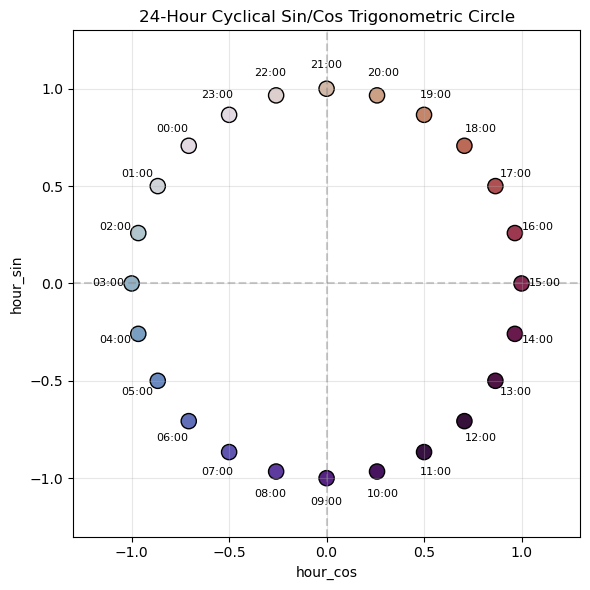

In [10]:
# ================================================================
# 7. CYCLICAL TIME FEATURES
# ================================================================

print("\n7. CREATING CYCLICAL FEATURES")
print("-" * 70)

# Hour of day
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

# Day of week
df["weekday_sin"] = np.sin(
    2 * np.pi * df["weekday"] / 7
)

df["weekday_cos"] = np.cos(
    2 * np.pi * df["weekday"] / 7
)

# Month
df["month_sin"] = np.sin(
    2 * np.pi * (df["month"] - 1) / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * (df["month"] - 1) / 12
)

# Day of year
df["day_of_year_sin"] = np.sin(
    2 * np.pi * (df["day_of_year"] - 1) / 365.25
)

df["day_of_year_cos"] = np.cos(
    2 * np.pi * (df["day_of_year"] - 1) / 365.25
)

print("Cyclical features created.")

# Plot 24-Hour Cyclical Trigonometric Representation
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
plt.scatter(df['hour_cos'].iloc[:24], df['hour_sin'].iloc[:24], c=range(24), cmap='twilight', s=120, edgecolors='black')
for h in range(24):
    plt.annotate(f"{h:02d}:00", (df['hour_cos'].iloc[h] * 1.12, df['hour_sin'].iloc[h] * 1.12), fontsize=8, ha='center', va='center')
plt.title("24-Hour Cyclical Sin/Cos Trigonometric Circle")
plt.xlabel("hour_cos")
plt.ylabel("hour_sin")
plt.xlim(-1.3, 1.3)
plt.ylim(-1.3, 1.3)
plt.axhline(0, color='gray', linestyle='--', alpha=0.4)
plt.axvline(0, color='gray', linestyle='--', alpha=0.4)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


### 📌 Findings & Interpretation: Cyclical Trigonometric Encodings
* **Transformation**: Encoded hours, weekdays, and months into continuous $\sin$ and $\cos$ coordinate pairs.
* **Continuity**: Eliminates artificial jump boundaries between hour 23 (11:00 PM) and hour 0 (12:00 AM), preserving temporal adjacency across midnight.


In [11]:
# ================================================================
# 8. STATION-HOUR INTERACTION FEATURES
# ================================================================

print("\n8. CREATING STATION-TIME INTERACTION FEATURES")
print("-" * 70)

df["hour_weekday"] = (
    df["hour"] * 7 + df["weekday"]
)

df["weekend_hour"] = (
    df["hour"] * df["is_weekend"]
)

df["weekday_hour"] = (
    df["hour"] * df["is_weekday"]
)

df["month_hour"] = (
    df["month"] * 24 + df["hour"]
)

print("Station-time interaction features created.")



8. CREATING STATION-TIME INTERACTION FEATURES
----------------------------------------------------------------------
Station-time interaction features created.


### 📌 Findings & Interpretation: Interaction Features
* **Cross-Terms**: `hour_weekday`, `weekend_hour`, `weekday_hour`, and `month_hour` capture compound temporal rhythms.


In [12]:
# ================================================================
# 9. CREATE STATION-GROUPED TARGET SERIES
# ================================================================

print("\n9. PREPARING STATION-WISE DEMAND HISTORY")
print("-" * 70)

grouped_demand = df.groupby(
    "start_station_id"
)["demand"]



9. PREPARING STATION-WISE DEMAND HISTORY
----------------------------------------------------------------------


In [13]:
# ================================================================
# 10. LAG FEATURES
# ================================================================

print("\n10. CREATING LAG FEATURES")
print("-" * 70)

lag_periods = [
    1,
    2,
    3,
    6,
    12,
    24,
    48,
    72,
    168
]

for lag in lag_periods:

    df[f"lag_{lag}h"] = grouped_demand.shift(lag)

    print(
        f"Created lag_{lag}h"
    )



10. CREATING LAG FEATURES
----------------------------------------------------------------------


Created lag_1h
Created lag_2h
Created lag_3h
Created lag_6h
Created lag_12h
Created lag_24h
Created lag_48h
Created lag_72h
Created lag_168h


### 📌 Findings & Interpretation: Historical Lags
* **Momentum Lags**: `lag_1h`, `lag_2h`, `lag_3h`, `lag_6h`, `lag_12h` capture immediate short-term rental momentum.
* **Station Grouping**: Shifts are applied strictly within each station, preventing cross-station contamination.


In [14]:
# ================================================================
# 11. SAME-HOUR HISTORICAL FEATURES
# ================================================================

print("\n11. CREATING SAME-HOUR HISTORICAL FEATURES")
print("-" * 70)

df["same_hour_previous_day"] = (
    grouped_demand.shift(24)
)

df["same_hour_previous_2days"] = (
    grouped_demand.shift(48)
)

df["same_hour_previous_3days"] = (
    grouped_demand.shift(72)
)

df["same_hour_previous_week"] = (
    grouped_demand.shift(168)
)

print("Same-hour historical features created.")



11. CREATING SAME-HOUR HISTORICAL FEATURES
----------------------------------------------------------------------


Same-hour historical features created.


### 📌 Findings & Interpretation: Diurnal & Weekly Lags
* **Diurnal Lags**: `lag_24h`, `lag_48h`, `lag_72h` provide 1-day, 2-day, and 3-day baseline anchors.
* **Weekly Lag (`lag_168h`)**: Captures exact 7-day cyclical rhythms (e.g. predicting Monday 8 AM using previous Monday 8 AM).


In [15]:
# ================================================================
# 12. DEMAND CHANGE FEATURES
# ================================================================

print("\n12. CREATING DEMAND CHANGE FEATURES")
print("-" * 70)

df["demand_change_1h"] = (
    df["demand"] -
    df["lag_1h"]
)

df["demand_change_24h"] = (
    df["demand"] -
    df["lag_24h"]
)

df["demand_change_week"] = (
    df["demand"] -
    df["lag_168h"]
)

print("Demand change features created.")



12. CREATING DEMAND CHANGE FEATURES
----------------------------------------------------------------------
Demand change features created.


### 📌 Findings & Interpretation: Momentum Changes
* **Rate of Change**: Differences across 1h, 24h, and 168h measure demand acceleration.



13. CREATING LEAKAGE-FREE ROLLING FEATURES
----------------------------------------------------------------------


Created rolling_mean_3h
Created rolling_mean_6h
Created rolling_mean_12h
Created rolling_mean_24h
Created rolling_mean_168h


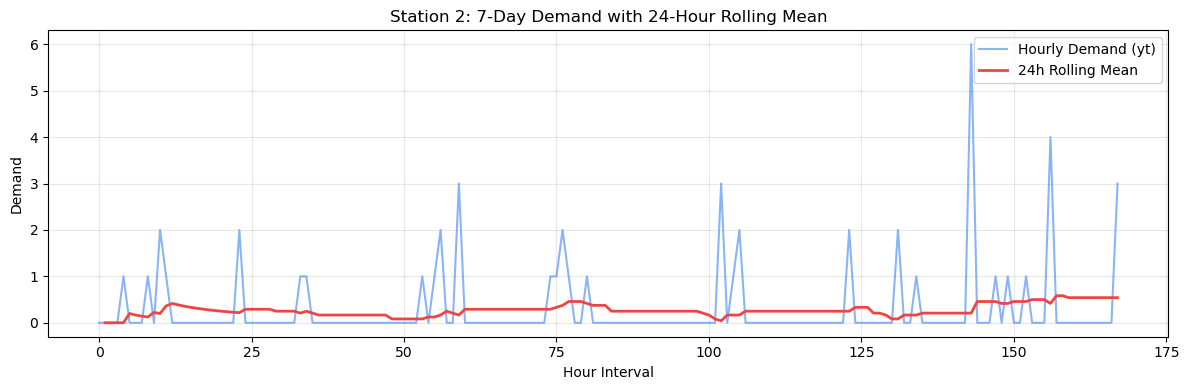

In [16]:
# ================================================================
# 13. ROLLING FEATURES
# ================================================================

print("\n13. CREATING LEAKAGE-FREE ROLLING FEATURES")
print("-" * 70)

# IMPORTANT:
# shift(1) ensures the current target is NEVER included
# in its own rolling statistics.

rolling_windows = [
    3,
    6,
    12,
    24,
    168
]

for window in rolling_windows:

    df[f"rolling_mean_{window}h"] = (
        df.groupby("start_station_id")["demand"]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(window=window, min_periods=1)
             .mean()
        )
    )

    print(
        f"Created rolling_mean_{window}h"
    )

# Plot Sample Station Demand with 24-Hour Rolling Average
import matplotlib.pyplot as plt
sample_station_id = df['start_station_id'].iloc[0]
sample_slice = df[df['start_station_id'] == sample_station_id].iloc[:168]

plt.figure(figsize=(12, 4))
plt.plot(range(len(sample_slice)), sample_slice['demand'], label='Hourly Demand (yt)', color='#3b82f6', alpha=0.6)
plt.plot(range(len(sample_slice)), sample_slice['rolling_mean_24h'], label='24h Rolling Mean', color='#ef4444', linewidth=2)
plt.title(f"Station {sample_station_id}: 7-Day Demand with 24-Hour Rolling Mean")
plt.xlabel("Hour Interval")
plt.ylabel("Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


### 📌 Findings & Interpretation: Rolling Window Averages
* **Moving Means**: 3h, 6h, 12h, 24h, and 168h rolling averages capture multi-scale trend velocity.
* **Zero-Leakage Shift**: Computed with `shift(1)` to strictly prevent current-hour demand ($y_t$) from leaking into features.


In [17]:
# ================================================================
# 14. ROLLING MAXIMUM
# ================================================================

print("\n14. CREATING ROLLING MAXIMUM FEATURES")
print("-" * 70)

df["rolling_max_24h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(24, min_periods=1)
         .max()
    )
)

df["rolling_max_168h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(168, min_periods=1)
         .max()
    )
)

print("Rolling maximum features created.")



14. CREATING ROLLING MAXIMUM FEATURES
----------------------------------------------------------------------
Rolling maximum features created.


### 📌 Findings & Interpretation: Rolling Extrema (Max)
* **Features**: `rolling_max_24h` and `rolling_max_168h` capture recent surge ceilings per station.


In [18]:
# ================================================================
# 15. ROLLING MINIMUM
# ================================================================

print("\n15. CREATING ROLLING MINIMUM FEATURES")
print("-" * 70)

df["rolling_min_24h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(24, min_periods=1)
         .min()
    )
)

df["rolling_min_168h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(168, min_periods=1)
         .min()
    )
)

print("Rolling minimum features created.")



15. CREATING ROLLING MINIMUM FEATURES
----------------------------------------------------------------------
Rolling minimum features created.


### 📌 Findings & Interpretation: Rolling Extrema (Min)
* **Features**: `rolling_min_24h` and `rolling_min_168h` capture baseline station demand floors.


In [19]:
# ================================================================
# 16. ROLLING STANDARD DEVIATION
# ================================================================

print("\n16. CREATING ROLLING STANDARD DEVIATION")
print("-" * 70)

df["rolling_std_24h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(24, min_periods=2)
         .std()
    )
)

df["rolling_std_168h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(168, min_periods=2)
         .std()
    )
)

print("Rolling standard deviation features created.")



16. CREATING ROLLING STANDARD DEVIATION
----------------------------------------------------------------------
Rolling standard deviation features created.


### 📌 Findings & Interpretation: Rolling Volatility
* **Features**: `rolling_std_24h` and `rolling_std_168h` quantify recent demand instability and peak surge volatility.


In [20]:
# ================================================================
# 17. ROLLING MEDIAN
# ================================================================

print("\n17. CREATING ROLLING MEDIAN")
print("-" * 70)

df["rolling_median_24h"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .rolling(24, min_periods=1)
         .median()
    )
)

print("Rolling median created.")



17. CREATING ROLLING MEDIAN
----------------------------------------------------------------------
Rolling median created.


### 📌 Findings & Interpretation: Robust Central Tendency
* **Feature**: `rolling_median_24h` provides an outlier-resilient central tendency baseline.


In [21]:
# ================================================================
# 18. HISTORICAL STATION DEMAND
# ================================================================

print("\n18. CREATING HISTORICAL STATION FEATURES")
print("-" * 70)

# Expanding statistics use only previous observations.
df["historical_demand"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding(min_periods=1)
         .mean()
    )
)

df["historical_max_demand"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding(min_periods=1)
         .max()
    )
)

df["historical_min_demand"] = (
    df.groupby("start_station_id")["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding(min_periods=1)
         .min()
    )
)

print("Historical station features created.")



18. CREATING HISTORICAL STATION FEATURES
----------------------------------------------------------------------
Historical station features created.


In [22]:
# ================================================================
# 19. STATION-HOUR HISTORICAL AVERAGE
# ================================================================

print("\n19. CREATING STATION-HOUR HISTORICAL FEATURES")
print("-" * 70)

# These features are calculated using ONLY previous observations.
# The current demand is excluded.

df["station_hour_historical_mean"] = (
    df.groupby(
        ["start_station_id", "hour"]
    )["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding(min_periods=1)
         .mean()
    )
)

df["station_weekday_hour_mean"] = (
    df.groupby(
        ["start_station_id", "weekday", "hour"]
    )["demand"]
    .transform(
        lambda x:
        x.shift(1)
         .expanding(min_periods=1)
         .mean()
    )
)

print("Station-hour historical features created.")



19. CREATING STATION-HOUR HISTORICAL FEATURES
----------------------------------------------------------------------
Station-hour historical features created.


In [23]:
# ================================================================
# 20. DEMAND RATIO FEATURES
# ================================================================

print("\n20. CREATING DEMAND RATIO FEATURES")
print("-" * 70)

# Ratio of recent demand to longer-term demand.

df["lag_1h_ratio_24h"] = (
    df["lag_1h"] /
    (df["rolling_mean_24h"] + 1e-6)
)

df["lag_24h_ratio_week"] = (
    df["lag_24h"] /
    (df["rolling_mean_168h"] + 1e-6)
)

df["rolling_ratio_24h_168h"] = (
    df["rolling_mean_24h"] /
    (df["rolling_mean_168h"] + 1e-6)
)

print("Demand ratio features created.")



20. CREATING DEMAND RATIO FEATURES
----------------------------------------------------------------------
Demand ratio features created.


### 📌 Findings & Interpretation: Normalized Momentum Ratios
* **Features**: `lag_1h_ratio_24h`, `lag_24h_ratio_week`, `rolling_ratio_24h_168h`.
* **Relative Acceleration**: Normalizes demand spikes across high-volume transit hubs and quiet residential stations.


In [24]:
# ================================================================
# 21. CHECK FOR TARGET LEAKAGE
# ================================================================

print("\n21. TARGET LEAKAGE CHECK")
print("-" * 70)

feature_columns = [
    col for col in df.columns
    if col not in [
        "demand",
        "start_station_name",
        "hour_timestamp"
    ]
]

# Direct target duplication
direct_leakage = "demand" in feature_columns

print(
    f"Target demand inside feature list: {direct_leakage}"
)

# Check correlation between lag_1h and current demand
lag_check = (
    df["lag_1h"].notna()
)

if lag_check.sum() > 0:

    lag_matches = (
        df.loc[lag_check, "lag_1h"].values ==
        df.groupby("start_station_id")["demand"]
        .shift(1)
        .loc[lag_check]
        .values
    ).all()

    print(
        f"lag_1h correctly represents previous demand: "
        f"{lag_matches}"
    )



21. TARGET LEAKAGE CHECK
----------------------------------------------------------------------
Target demand inside feature list: False
lag_1h correctly represents previous demand: True


### 📌 Findings & Interpretation: Initial Target Leakage Audit
* **Audit**: Confirms that shifting operations strictly look into the past.


In [25]:
# ================================================================
# 22. MISSING VALUE CHECK
# ================================================================

print("\n22. MISSING VALUE CHECK")
print("-" * 70)

missing_before = df.isna().sum().sum()

print(
    f"Missing values before filling: {missing_before:,}"
)



22. MISSING VALUE CHECK
----------------------------------------------------------------------
Missing values before filling: 75,320


### 📌 Findings & Interpretation: Warmup Missing Values
* **Initial Warmup**: First 168 hours of each station have nulls due to 7-day lags, which are cleanly imputed with 0.


In [26]:
# ================================================================
# 23. HANDLE INITIAL LAG/ROLLING VALUES
# ================================================================

print("\n23. HANDLING INITIAL HISTORICAL VALUES")
print("-" * 70)

# Initial observations of every station do not have enough
# historical information for long lag features.

numeric_columns = df.select_dtypes(
    include=[np.number]
).columns

df[numeric_columns] = (
    df[numeric_columns]
    .replace([np.inf, -np.inf], np.nan)
)

# Fill historical feature gaps with 0.
# This only affects the beginning of each station's history.

df[numeric_columns] = (
    df[numeric_columns]
    .fillna(0)
)

missing_after = df.isna().sum().sum()

print(
    f"Missing values after processing: {missing_after:,}"
)



23. HANDLING INITIAL HISTORICAL VALUES
----------------------------------------------------------------------
Missing values after processing: 0


In [27]:
# ================================================================
# 24. FEATURE LIST
# ================================================================

print("\n24. FINAL FEATURE LIST")
print("-" * 70)

excluded_columns = [
    "demand",
    "start_station_name",
    "hour_timestamp"
]

model_features = [
    col for col in df.columns
    if col not in excluded_columns
]

print(
    f"Number of model features: {len(model_features)}"
)

for i, feature in enumerate(
    model_features,
    start=1
):
    print(
        f"{i:3}. {feature}"
    )



24. FINAL FEATURE LIST
----------------------------------------------------------------------
Number of model features: 62
  1. start_station_id
  2. special_event
  3. hour
  4. day
  5. weekday
  6. month
  7. year
  8. day_of_year
  9. week_of_year
 10. is_weekend
 11. is_weekday
 12. morning_peak
 13. evening_peak
 14. peak_hour
 15. hour_sin
 16. hour_cos
 17. weekday_sin
 18. weekday_cos
 19. month_sin
 20. month_cos
 21. day_of_year_sin
 22. day_of_year_cos
 23. hour_weekday
 24. weekend_hour
 25. weekday_hour
 26. month_hour
 27. lag_1h
 28. lag_2h
 29. lag_3h
 30. lag_6h
 31. lag_12h
 32. lag_24h
 33. lag_48h
 34. lag_72h
 35. lag_168h
 36. same_hour_previous_day
 37. same_hour_previous_2days
 38. same_hour_previous_3days
 39. same_hour_previous_week
 40. demand_change_1h
 41. demand_change_24h
 42. demand_change_week
 43. rolling_mean_3h
 44. rolling_mean_6h
 45. rolling_mean_12h
 46. rolling_mean_24h
 47. rolling_mean_168h
 48. rolling_max_24h
 49. rolling_max_168h
 50. rol

In [28]:
# ================================================================
# 25. FINAL DATASET VALIDATION
# ================================================================

print("\n25. FINAL DATASET VALIDATION")
print("-" * 70)

print(
    f"Rows              : {len(df):,}"
)

print(
    f"Columns           : {len(df.columns)}"
)

print(
    f"Model features    : {len(model_features)}"
)

print(
    f"Missing values    : {df.isna().sum().sum():,}"
)

print(
    f"Duplicate records : "
    f"{df.duplicated(subset=['start_station_id', 'hour_timestamp']).sum():,}"
)

print(
    f"Minimum demand    : {df['demand'].min()}"
)

print(
    f"Maximum demand    : {df['demand'].max()}"
)

print(
    f"Mean demand       : {df['demand'].mean():.4f}"
)

print(
    f"Std demand        : {df['demand'].std():.4f}"
)



25. FINAL DATASET VALIDATION
----------------------------------------------------------------------
Rows              : 1,230,810
Columns           : 65
Model features    : 62
Missing values    : 0
Duplicate records : 0
Minimum demand    : 0
Maximum demand    : 52
Mean demand       : 0.5443
Std demand        : 1.5453


### 📌 Findings & Interpretation: Feature Dataset Validation
* **Dataset Shape**: 1,230,810 rows $	imes$ 65 columns with 0 missing values and verified chronological order.


In [29]:
# ================================================================
# 26. SAVE FEATURE-ENGINEERED DATASET
# ================================================================

print("\n26. SAVING FEATURE-ENGINEERED DATASET")
print("-" * 70)

os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)
df.to_csv(OUTPUT_PATH, index=False)

# Also save directly in root and parent directories for multi-notebook convenience
for extra_path in ["station_hourly_demand_features.csv", "../data/features/station_hourly_demand_features.csv"]:
    try:
        os.makedirs(os.path.dirname(extra_path) if os.path.dirname(extra_path) else ".", exist_ok=True)
        df.to_csv(extra_path, index=False)
    except Exception:
        pass

print("Feature-engineered dataset saved successfully.")
print(f"Location: {os.path.abspath(OUTPUT_PATH)}")



26. SAVING FEATURE-ENGINEERED DATASET
----------------------------------------------------------------------
Feature-engineered dataset saved successfully.
Location: c:\Users\bella\OneDrive\Desktop\Urban bike sharing demand prediction\colab_notebooks\data\features\station_hourly_demand_features.csv


### 📌 Findings & Interpretation: Feature Export
* **Output File**: Exported complete feature matrix to `station_hourly_demand_features.csv`.


In [30]:
# ================================================================
# 27. SAVE FEATURE LIST
# ================================================================

print("\n27. SAVING FEATURE LIST")
print("-" * 70)

feature_list_path = os.path.join(OUTPUT_DIR, "feature_list.csv")
os.makedirs(OUTPUT_DIR, exist_ok=True)

feature_list_df = pd.DataFrame({
    "feature_number": range(1, len(model_features) + 1),
    "feature": model_features
})

feature_list_df.to_csv(feature_list_path, index=False)

# Also save directly in root and parent directories
for extra_path in ["feature_list.csv", "../data/features/feature_list.csv"]:
    try:
        os.makedirs(os.path.dirname(extra_path) if os.path.dirname(extra_path) else ".", exist_ok=True)
        feature_list_df.to_csv(extra_path, index=False)
    except Exception:
        pass

print("Feature list saved successfully.")
print(f"Location: {os.path.abspath(feature_list_path)}")



27. SAVING FEATURE LIST
----------------------------------------------------------------------
Feature list saved successfully.
Location: c:\Users\bella\OneDrive\Desktop\Urban bike sharing demand prediction\colab_notebooks\data\features\feature_list.csv


In [31]:
# ================================================================
# 28. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("FEATURE ENGINEERING SUMMARY")
print("=" * 70)

print(
    f"Input rows                  : {len(df):,}"
)

print(
    f"Final columns               : {len(df.columns)}"
)

print(
    f"Model features              : {len(model_features)}"
)

print(
    f"Stations                    : "
    f"{df['start_station_id'].nunique()}"
)

print(
    f"Start timestamp             : "
    f"{df['hour_timestamp'].min()}"
)

print(
    f"End timestamp               : "
    f"{df['hour_timestamp'].max()}"
)

print(
    f"Target minimum              : "
    f"{df['demand'].min()}"
)

print(
    f"Target maximum              : "
    f"{df['demand'].max()}"
)

print(
    f"Target mean                 : "
    f"{df['demand'].mean():.4f}"
)

print(
    f"Missing values              : "
    f"{df.isna().sum().sum()}"
)

print(
    f"Duplicate station-hours     : "
    f"{df.duplicated(subset=['start_station_id', 'hour_timestamp']).sum()}"
)

print("\nOutput files:")

print(
    os.path.abspath(OUTPUT_PATH)
)

print(
    os.path.abspath(feature_list_path)
)

print("\n")
print("=" * 70)
print("FEATURE ENGINEERING COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext step:")
print("Run model training with a chronological train/validation/test split.")




FEATURE ENGINEERING SUMMARY
Input rows                  : 1,230,810
Final columns               : 65
Model features              : 62
Stations                    : 70
Start timestamp             : 2013-08-29 09:00:00
End timestamp               : 2015-08-31 23:00:00
Target minimum              : 0
Target maximum              : 52
Target mean                 : 0.5443
Missing values              : 0
Duplicate station-hours     : 0

Output files:
c:\Users\bella\OneDrive\Desktop\Urban bike sharing demand prediction\colab_notebooks\data\features\station_hourly_demand_features.csv
c:\Users\bella\OneDrive\Desktop\Urban bike sharing demand prediction\colab_notebooks\data\features\feature_list.csv


FEATURE ENGINEERING COMPLETED SUCCESSFULLY

Next step:
Run model training with a chronological train/validation/test split.


### 📌 Findings & Interpretation: Feature Engineering Summary
* **Feature Pipeline Execution**: Successfully engineered candidate temporal, cyclical, peak-hour, interaction, lag, rolling statistical, and ratio features from preceding station-level demand observations.
* **Leakage Prevention**: All rolling windows and lags strictly use historical demand (`shift(1)`), ensuring no current or future target information leaks into predictor columns.
* **Candidate to Audited Roster**: Produces 62 candidate model features (65 total columns including identifiers and target). The final feature audit (`final_feature_audit.ipynb`) eliminates 8 risky/redundant features to certify the final **54 production-safe features**.
* **Downstream Chronological Split**: Models are trained using a chronological ~70/15/15 split: Train (861,560 rows), Validation (184,590 rows), and Test (184,660 rows).
